# CT4101 Milestone 3: Model Comparison Checkpoint
**Project:** Predicting whether a Pokémon is Legendary (binary classification)
**Author:** Cian Flanagan

This notebook builds on `01_data_audit_and_baseline.ipynb`. It uses the same train/test split, the same preprocessing and the same evaluation protocol, so every model is compared fairly. The held-out test set is not used anywhere in this notebook.

## 1. Setup and the same split as Milestone 2
This cell imports the libraries and sets a fixed random seed (42) so my results can be repeated. The paths point to the data and figures folders, and work whether the notebook is run from the project folder or from `notebooks/`.

In [3]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

# Find the project folder: it is the folder that contains data/pokemon.csv
ROOT = Path.cwd()
if not (ROOT / "data" / "pokemon.csv").exists():
    ROOT = ROOT.parent
DATA_PATH = ROOT / "data" / "pokemon.csv"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Cannot find {DATA_PATH}. Save this notebook inside the project's notebooks/ folder, next to data/pokemon.csv.")
print("Using data file:", DATA_PATH)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

Using data file: c:\Users\Cian\Downloads\233891703_2 (1)\data\pokemon.csv


This cell loads the data and recreates exactly the same stratified 80/20 train/test split as Milestone 2. The `assert` stops the notebook with an error if the split ever changes, so all models are compared on the same data. The test set stays locked.

In [4]:
df = pd.read_csv(DATA_PATH)

num_cols = ["height_dm", "weight_hg", "hp", "attack", "defense",
            "special_attack", "special_defense", "speed"]
cat_cols = ["type_1", "type_2", "generation"]
target_col = "is_legendary"

X = df[num_cols + cat_cols].copy()
X["type_2"] = X["type_2"].fillna("none")
y = df[target_col].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

assert (len(X_train), y_train.sum(), len(X_test), y_test.sum()) == (1080, 96, 271, 24)
print(f"Train: {len(X_train)} rows, {y_train.sum()} Legendary | Test: {len(X_test)} rows, {y_test.sum()} Legendary (locked)")

Train: 1080 rows, 96 Legendary | Test: 271 rows, 24 Legendary (locked)


This cell defines the preprocessing: median imputation and scaling for the numeric columns and a "none" fill plus one-hot encoding for the categorical columns. It also sets up 5-fold stratified cross-validation and the metrics I will report. Everything is inside a pipeline so it is only fitted on the training folds to avoids data leakage.

In [5]:
numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
categorical_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="constant", fill_value="none")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocess = ColumnTransformer([
    ("num", numeric_pipe, num_cols),
    ("cat", categorical_pipe, cat_cols),
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
}

## 2. Evaluation helper
This function cross-validates any model on the training set only and returns its average scores. Using the same function for every model keeps the comparison fair.

In [6]:
def make_pipeline(model):
    return Pipeline([("prep", preprocess), ("model", model)])

def evaluate(name, estimator):
    """Cross-validate on the training set and return one row of metrics."""
    res = cross_validate(estimator, X_train, y_train, cv=cv, scoring=scoring)
    row = {"model": name}
    for m in scoring:
        row[m] = res[f"test_{m}"].mean()
    row["f1_std"] = res["test_f1"].std()
    return row

## 3. Baselines and learned models

**Models and main settings**
- Dummy (most_frequent): always predicts "not Legendary". This is the baseline to beat.
- Dummy (stratified): guesses randomly in the class proportions.
- Logistic Regression (reference from Milestone 2): `max_iter=1000`.
- K-Nearest Neighbours: default settings, k = 5, uniform weights. It classifies by a vote of the 5 most similar Pokémon.
- Decision Tree: default settings, no depth limit, `random_state=42`. It is a flowchart of yes/no questions on the stats.
- Random Forest: default settings, 100 trees, `random_state=42`. It averages many trees trained on random parts of the data.

I used default settings for all models so the comparison is simple and fair. No tuning was done, and tuning is listed as a next step.

This cell runs all six models under the same 5-fold cross-validation and puts the results in one table.

In [7]:
default_models = {
    "Dummy (most_frequent)": DummyClassifier(strategy="most_frequent"),
    "Dummy (stratified)": DummyClassifier(strategy="stratified", random_state=RANDOM_STATE),
    "Logistic Regression (reference)": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "KNN (k=5)": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE),
}

rows = [evaluate(name, make_pipeline(model)) for name, model in default_models.items()]
results = pd.DataFrame(rows).set_index("model").round(3)
results

,accuracy,balanced_accuracy,precision,recall,f1,f1_std
model,,,,,,
Dummy (most_frequent),0.911,0.500,0.000,0.000,0.000,0.000
Dummy (stratified),0.853,0.496,0.080,0.063,0.070,0.024
Logistic Regression (reference),0.934,0.714,0.717,0.447,0.535,0.129
KNN (k=5),0.924,0.677,0.624,0.376,0.457,0.104
Decision Tree,0.926,0.786,0.597,0.615,0.597,0.055
Random Forest,0.951,0.743,0.917,0.491,0.637,0.079


**Reading the table**
- All three learned models beat both dummies on F1 for the Legendary class.
- Random Forest has the best F1 (about 0.64) and very high precision (about 0.92), but its recall is only about 0.49.
- Decision Tree has the highest recall (about 0.62) but lower precision (about 0.60).
- KNN is the weakest of the three (F1 about 0.46).
- With only 96 Legendary Pokémon in training, F1 varies between folds (see `f1_std`), so small differences should not be over-interpreted.
- Accuracy is 91-95% for every model, so it cannot be used to pick a winner.

This chart plots F1 for each model so the comparison is easy to see. The error bars show how much F1 varies between the 5 folds.

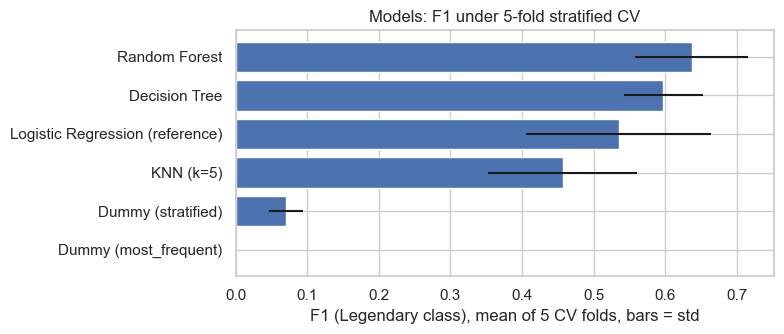

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.5))
order = results["f1"].sort_values()
ax.barh(order.index, order.values, xerr=results.loc[order.index, "f1_std"], color="#4C72B0")
ax.set_xlabel("F1 (Legendary class), mean of 5 CV folds, bars = std")
ax.set_title("Models: F1 under 5-fold stratified CV")
plt.tight_layout()
plt.savefig(FIG_DIR / "m3_f1_comparison.png", dpi=150)
plt.show()